# Tarea P4: detección y seguimiento de personas, vehículos y matrículas

Pasos:
1. Preparación del dataset de matrículas (`dataset_raw`) en formato YOLO (train / val / test).
2. Entrenamiento de un detector de matrículas con YOLO (`yolo11n.pt` como punto de partida) y análisis del entrenamiento.
3. Prototipo sobre `TGC23_PdH_C0056cut.mp4`: detección + seguimiento de personas y vehículos, detección de matrículas, conteo por clase, vídeo resultado y CSV.
4. Extras: flujo de personas/vehículos por dirección y anonimización (vídeo con personas y matrículas difuminadas).

## 1. Preparación del dataset

Cada imagen de `dataset_raw/annotations/images` tiene un `.json` homónimo en `dataset_raw/annotations` con una lista de objetos
`{"rectangle": [xc, yc, w, h], "plate": "texto"}`. Las coordenadas ya están normalizadas y referidas al **centro** del contenedor
(se comprobó dibujándolas), es decir, el mismo formato que espera YOLO, con una única clase `matricula` (id 0).

- Se descartan cajas degeneradas (ancho/alto ≤ 0) y se recortan a la imagen.
- Reparto aleatorio (semilla fija) como sugiere el enunciado: 80 % train+val / 20 % test, y dentro del primero 80/20 → **64 % train, 16 % val, 20 % test**.
- Las fotos originales son muy grandes (≈7 GB en total); se guardan reescaladas a 1280 px de lado mayor (las etiquetas normalizadas no cambian), lo que acelera mucho la carga de datos al entrenar en CPU.
  `cv2.imread` aplica la orientación EXIF, igual que la herramienta con la que se anotó, así que las imágenes guardadas quedan coherentes con las etiquetas.

In [1]:
import os, json, glob, random, shutil
import numpy as np
import cv2

RAW_DIR   = 'dataset_raw/annotations'
RAW_IMGS  = os.path.join(RAW_DIR, 'images')
DATA_DIR  = os.path.abspath('dataset_matriculas')
YAML_PATH = os.path.join(DATA_DIR, 'matriculas.yaml')
MAX_SIDE  = 1280

def lee_etiquetas(json_path):
    # Devuelve lista de (xc, yc, w, h) válidos y normalizados
    cajas = []
    for o in json.load(open(json_path, encoding='utf-8')):
        xc, yc, w, h = map(float, o['rectangle'])
        if w <= 0 or h <= 0:
            continue
        x1, y1 = max(0., xc - w/2), max(0., yc - h/2)
        x2, y2 = min(1., xc + w/2), min(1., yc + h/2)
        if x2 - x1 < 1e-4 or y2 - y1 < 1e-4:
            continue
        cajas.append(((x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1))
    return cajas

# Emparejar imágenes y anotaciones por nombre base
imgs = {os.path.splitext(f)[0]: f for f in os.listdir(RAW_IMGS)}
pares = []
for jp in sorted(glob.glob(os.path.join(RAW_DIR, '*.json'))):
    base = os.path.splitext(os.path.basename(jp))[0]
    if base in imgs:
        pares.append((base, imgs[base], lee_etiquetas(jp)))
sin_img = len(glob.glob(os.path.join(RAW_DIR, '*.json'))) - len(pares)
print(f'Pares imagen/anotación: {len(pares)}  (json sin imagen: {sin_img})')
print(f'Matrículas válidas: {sum(len(p[2]) for p in pares)}')

# Reparto aleatorio 64/16/20
random.seed(42)
random.shuffle(pares)
n = len(pares)
n_test = int(round(0.2 * n))
n_val  = int(round(0.2 * (n - n_test)))
splits = {'test': pares[:n_test], 'val': pares[n_test:n_test+n_val], 'train': pares[n_test+n_val:]}

if not os.path.exists(YAML_PATH):
    for split, lista in splits.items():
        os.makedirs(os.path.join(DATA_DIR, split, 'images'), exist_ok=True)
        os.makedirs(os.path.join(DATA_DIR, split, 'labels'), exist_ok=True)
        for base, fname, cajas in lista:
            img = cv2.imread(os.path.join(RAW_IMGS, fname))
            if img is None:
                print('No se pudo leer', fname); continue
            h, w = img.shape[:2]
            s = MAX_SIDE / max(h, w)
            if s < 1:
                img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
            cv2.imwrite(os.path.join(DATA_DIR, split, 'images', base + '.jpg'), img, [cv2.IMWRITE_JPEG_QUALITY, 92])
            with open(os.path.join(DATA_DIR, split, 'labels', base + '.txt'), 'w') as f:
                for xc, yc, bw, bh in cajas:
                    f.write(f'0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n')
    with open(YAML_PATH, 'w') as f:
        f.write(f"path: {DATA_DIR.replace(os.sep, '/')}\n"
                "train: train/images\nval: val/images\ntest: test/images\n\n"
                "nc: 1\nnames: ['matricula']\n")

for split in ['train', 'val', 'test']:
    labs = glob.glob(os.path.join(DATA_DIR, split, 'labels', '*.txt'))
    nobj = sum(len(open(l).read().split('\n')) - 1 for l in labs)
    print(f'{split:5s}: {len(labs):4d} imágenes, {nobj:4d} matrículas')
print(open(YAML_PATH).read())

Pares imagen/anotación: 2387  (json sin imagen: 31)
Matrículas válidas: 5235
train: 1528 imágenes, 3362 matrículas
val  :  382 imágenes,  828 matrículas
test :  477 imágenes, 1045 matrículas
path: C:/Users/Usuario/Desktop/puta_uni/PracticasVC/VC/P4/dataset_matriculas
train: train/images
val: val/images
test: test/images

nc: 1
names: ['matricula']



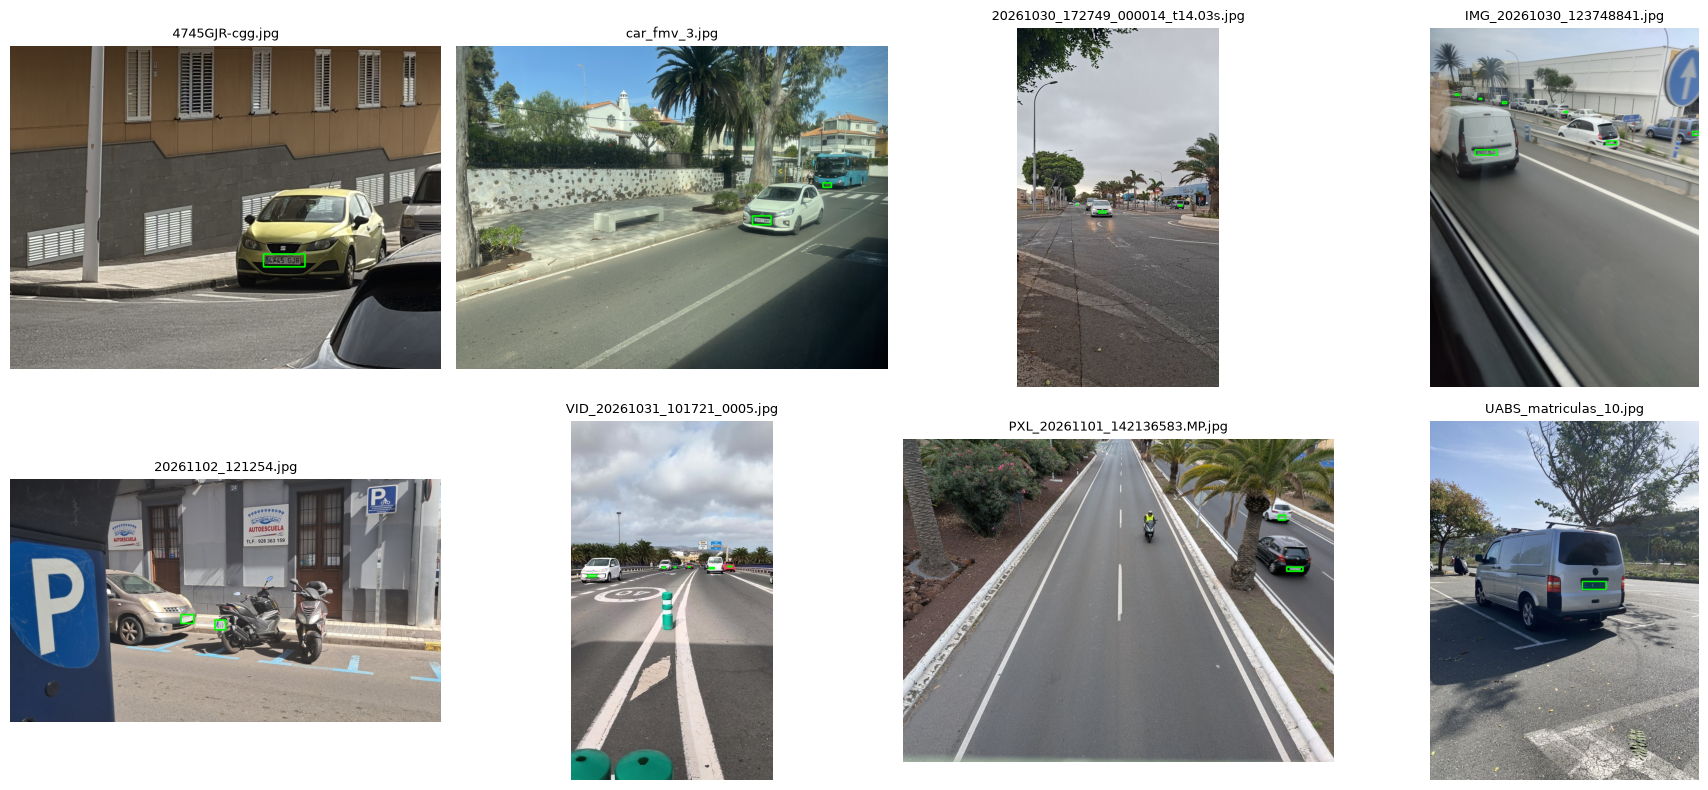

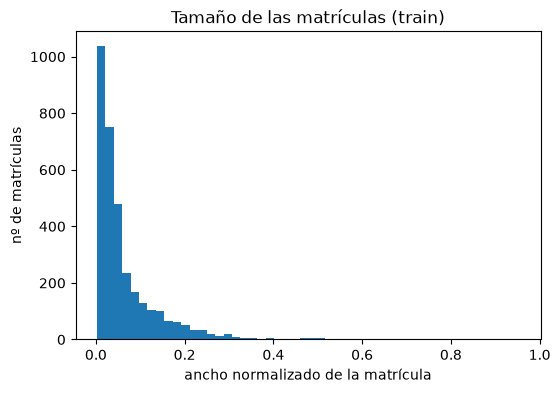

In [2]:
import matplotlib.pyplot as plt

# Algunas muestras del conjunto de entrenamiento con sus anotaciones
muestras = sorted(glob.glob(os.path.join(DATA_DIR, 'train', 'images', '*.jpg')))
random.seed(1)
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for ax, ip in zip(axs.ravel(), random.sample(muestras, 8)):
    img = cv2.imread(ip)
    h, w = img.shape[:2]
    lp = ip.replace(os.sep + 'images' + os.sep, os.sep + 'labels' + os.sep).replace('.jpg', '.txt')
    for linea in open(lp).read().split('\n'):
        if linea.strip():
            _, xc, yc, bw, bh = map(float, linea.split())
            cv2.rectangle(img, (int((xc-bw/2)*w), int((yc-bh/2)*h)), (int((xc+bw/2)*w), int((yc+bh/2)*h)), (0, 255, 0), 4)
    ax.imshow(img[:, :, ::-1]); ax.set_title(os.path.basename(ip), fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

# Distribución del tamaño relativo de las matrículas
wh = np.array([list(map(float, l.split()[3:])) for lp in glob.glob(os.path.join(DATA_DIR, 'train', 'labels', '*.txt'))
               for l in open(lp).read().split('\n') if l.strip()])
plt.figure(figsize=(6, 4))
plt.hist(wh[:, 0], bins=50)
plt.xlabel('ancho normalizado de la matrícula'); plt.ylabel('nº de matrículas'); plt.title('Tamaño de las matrículas (train)')
plt.show()

## 2. Entrenamiento del detector de matrículas (YOLO)

Se parte de `yolo11n.pt` (preentrenado en COCO) y se ajusta a la clase única *matricula*. Al no disponer de GPU el entrenamiento se hace en CPU
(AMD Ryzen 7 5700G). Parámetros: `imgsz=640`, `batch=16`, early stopping con `patience=10`.

> El entrenamiento en CPU lleva varias horas, por eso la celda sólo entrena si no existen ya los pesos `best.pt`
> (el entrenamiento se lanzó con exactamente esta llamada y sus resultados quedan en `runs/detect/matriculas_yolo11n`).

In [3]:
from ultralytics import YOLO

TRAIN_NAME = 'matriculas_yolo11n'
TRAIN_DIR  = os.path.abspath(os.path.join('runs', 'detect', TRAIN_NAME))
BEST_PT    = os.path.join(TRAIN_DIR, 'weights', 'best.pt')
EPOCHS     = 40

if not os.path.exists(BEST_PT):
    modelo = YOLO('yolo11n.pt')
    modelo.train(data=YAML_PATH, epochs=EPOCHS, imgsz=640, batch=16, device='cpu', workers=8,
                 patience=10, project=os.path.abspath(os.path.join('runs', 'detect')), name=TRAIN_NAME,
                 exist_ok=True, seed=0, plots=True)
else:
    print('Pesos ya entrenados:', BEST_PT)

Pesos ya entrenados: c:\Users\Usuario\Desktop\puta_uni\PracticasVC\VC\P4\runs\detect\matriculas_yolo11n\weights\best.pt


### Análisis del entrenamiento

Evolución de las funciones de pérdida (caja, clasificación y DFL) en entrenamiento y validación, y de las métricas en validación
(precisión, *recall*, mAP@0.5 y mAP@0.5:0.95).

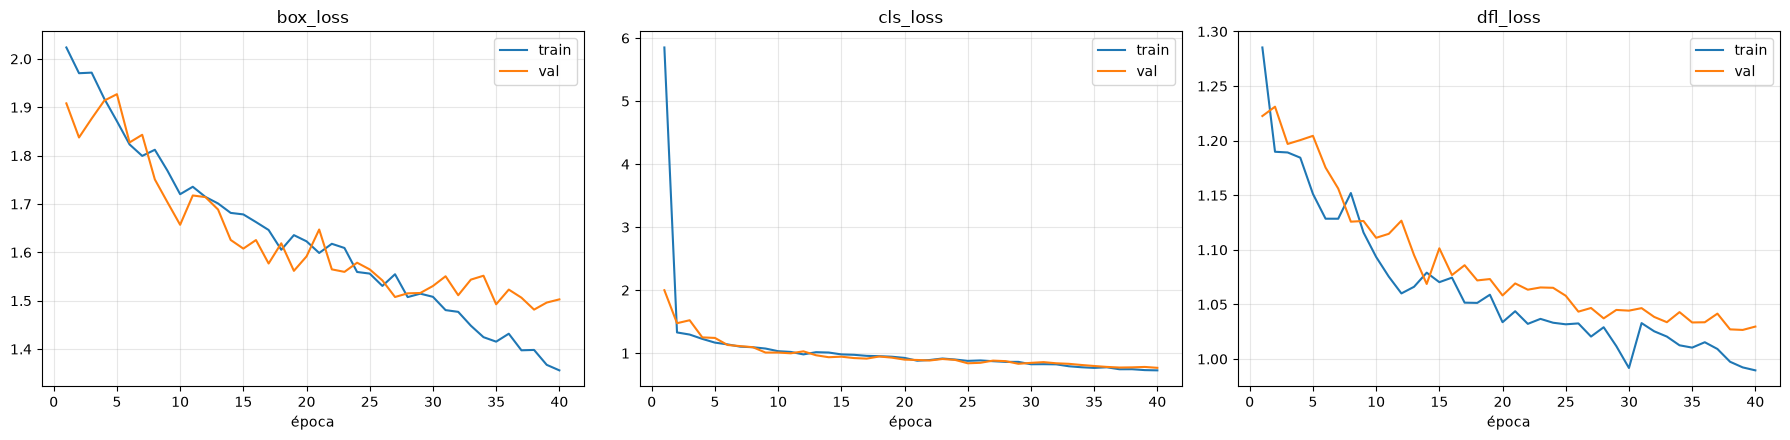

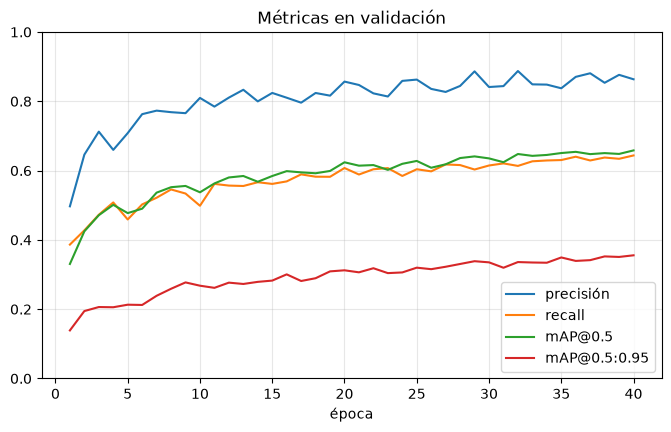

Épocas entrenadas: 40. Mejor época: 40 -> P=0.864  R=0.644  mAP50=0.658  mAP50-95=0.356


In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

if 'TRAIN_DIR' not in globals():
    TRAIN_DIR = os.path.abspath(os.path.join('runs', 'detect', 'matriculas_yolo11n'))

res = pd.read_csv(os.path.join(TRAIN_DIR, 'results.csv'))
res.columns = [c.strip() for c in res.columns]

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for k, nombre in enumerate(['box_loss', 'cls_loss', 'dfl_loss']):
    axs[k].plot(res['epoch'], res[f'train/{nombre}'], label='train')
    axs[k].plot(res['epoch'], res[f'val/{nombre}'], label='val')
    axs[k].set_title(nombre); axs[k].set_xlabel('época'); axs[k].legend(); axs[k].grid(alpha=.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4.5))
for m, etiqueta in [('metrics/precision(B)', 'precisión'), ('metrics/recall(B)', 'recall'),
                    ('metrics/mAP50(B)', 'mAP@0.5'), ('metrics/mAP50-95(B)', 'mAP@0.5:0.95')]:
    plt.plot(res['epoch'], res[m], label=etiqueta)
plt.xlabel('época'); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend(); plt.title('Métricas en validación')
plt.show()

mejor = res.loc[res['metrics/mAP50-95(B)'].idxmax()]
print(f"Épocas entrenadas: {len(res)}. Mejor época: {int(mejor['epoch'])} -> "
      f"P={mejor['metrics/precision(B)']:.3f}  R={mejor['metrics/recall(B)']:.3f}  "
      f"mAP50={mejor['metrics/mAP50(B)']:.3f}  mAP50-95={mejor['metrics/mAP50-95(B)']:.3f}")

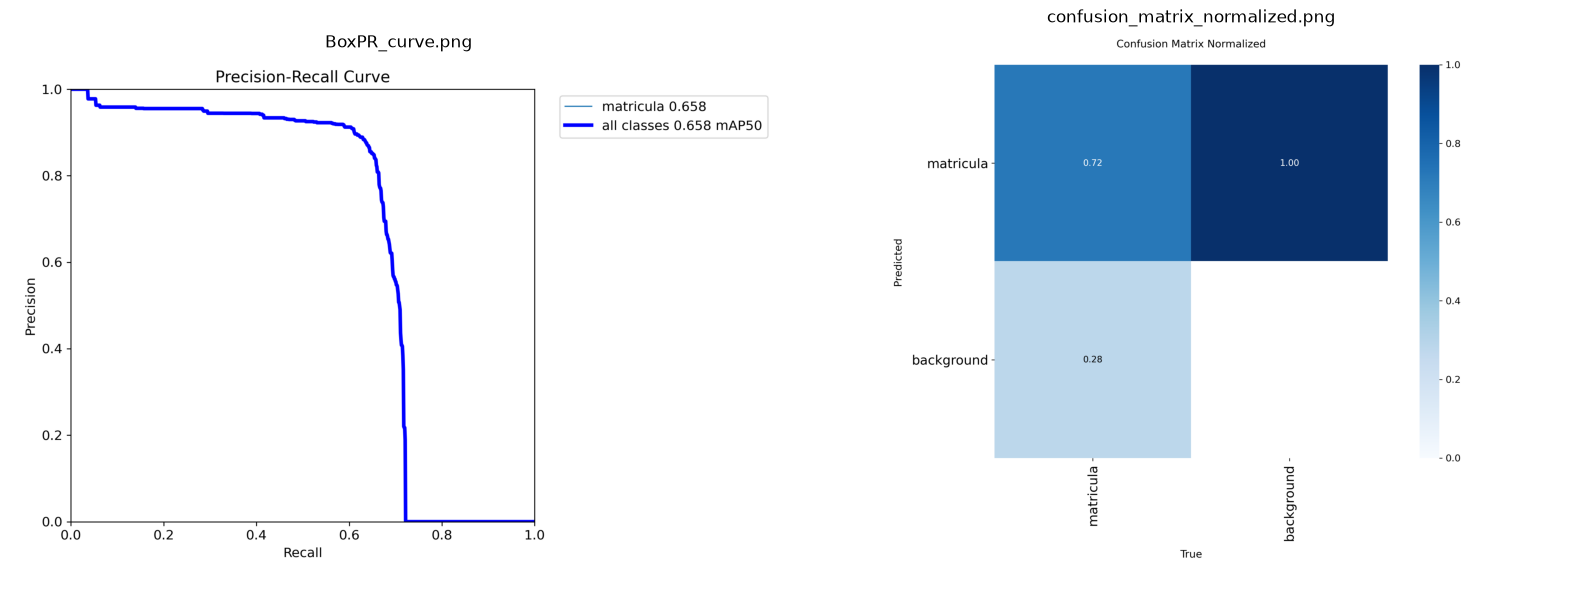

In [5]:
# Curvas y matriz de confusión generadas por ultralytics
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for ax, f in zip(axs, ['BoxPR_curve.png', 'confusion_matrix_normalized.png']):
    p = os.path.join(TRAIN_DIR, f)
    if os.path.exists(p):
        ax.imshow(plt.imread(p))
    ax.set_title(f); ax.axis('off')
plt.tight_layout(); plt.show()

### Evaluación sobre el conjunto de test

El 20 % de test no se ha usado ni para entrenar ni para escoger la mejor época, así que da una estimación honesta del rendimiento.

Ultralytics 8.4.210  Python-3.11.14 torch-2.15.0+cpu CPU (AMD Ryzen 7 5700G with Radeon Graphics)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 592.3±142.1 MB/s, size: 371.4 KB)
val: Scanning C:\Users\Usuario\Desktop\puta_uni\PracticasVC\VC\P4\dataset_matriculas\test\labels.cache... 477 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 477/477  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 1.5it/s 20.5s0.6ss
                   all        477       1045      0.889        0.6      0.619      0.334
Speed: 2.0ms preprocess, 31.7ms inference, 0.0ms loss, 0.4ms postprocess per image
TEST -> P=0.889  R=0.600  mAP50=0.619  mAP50-95=0.334


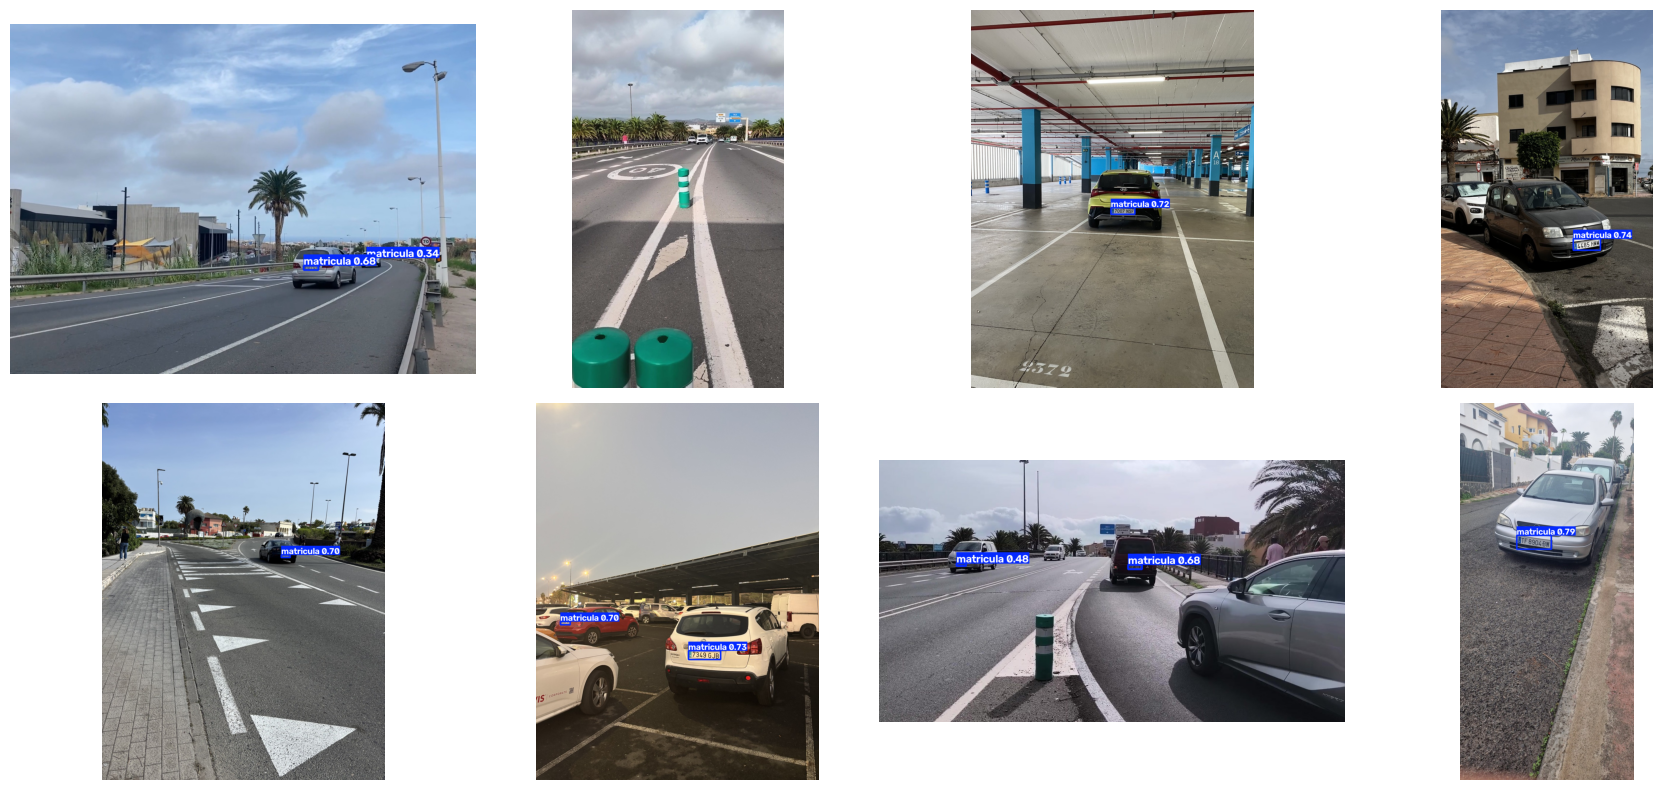

In [6]:
modelo_mat = YOLO(BEST_PT)
met = modelo_mat.val(data=YAML_PATH, split='test', imgsz=640, batch=16, device='cpu', plots=False, verbose=False,
                     project=os.path.abspath(os.path.join('runs', 'detect')), name=TRAIN_NAME + '_test', exist_ok=True)
print(f'TEST -> P={met.box.mp:.3f}  R={met.box.mr:.3f}  mAP50={met.box.map50:.3f}  mAP50-95={met.box.map:.3f}')

# Predicciones de ejemplo sobre imágenes de test
tests = sorted(glob.glob(os.path.join(DATA_DIR, 'test', 'images', '*.jpg')))
random.seed(3)
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for ax, ip in zip(axs.ravel(), random.sample(tests, 8)):
    r = modelo_mat(ip, imgsz=640, verbose=False)[0]
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Prototipo sobre el vídeo `TGC23_PdH_C0056cut.mp4`

- **Personas y vehículos**: `yolo11n.pt` en modo seguimiento (BoT-SORT, `persist=True`) restringido a las clases COCO
  *person, bicycle, car, motorcycle, bus, truck*.
- **Matrículas**: para cada vehículo con motor seguido (coche, moto, bus, camión) se recorta su caja (con un pequeño margen) y se pasa al detector de matrículas
  entrenado; se queda la matrícula de mayor confianza. Trabajar sobre el recorte hace que la matrícula ocupe más píxeles y que
  cada matrícula quede asociada a su vehículo.
- **Conteo**: número de identificadores de seguimiento distintos por clase (un objeto cuenta una sola vez aunque aparezca en muchos fotogramas).
  Para evitar contar identificadores espurios se exige que un track aparezca en al menos `MIN_FRAMES` fotogramas.
- **Salidas** (carpeta `resultados/`): `resultado.mp4` con las detecciones, `anonimizado.mp4` (extra) y `detecciones.csv` con el formato propuesto.
- `texto_matricula` queda vacío: el reconocimiento del texto (OCR) es la segunda parte de la práctica (P4b).

In [7]:
from collections import defaultdict

VIDEO      = 'C0142.MP4'
OUT_DIR    = 'resultados'
os.makedirs(OUT_DIR, exist_ok=True)

CLASES     = {0: 'persona', 1: 'bicicleta', 2: 'coche', 3: 'moto', 5: 'autobus', 7: 'camion'}
CON_MATRICULA = {2, 3, 5, 7}
COLORES    = {0: (0, 200, 255), 1: (255, 160, 0), 2: (0, 255, 0), 3: (255, 0, 255), 5: (255, 255, 0), 7: (0, 128, 255)}
CONF_OBJ   = 0.30
CONF_MAT   = 0.30
MIN_FRAMES = 5

modelo_obj = YOLO('yolo11n.pt')
modelo_mat = YOLO(BEST_PT)

cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_res  = cv2.VideoWriter(os.path.join(OUT_DIR, 'resultado.mp4'), fourcc, fps, (W, H))
out_anon = cv2.VideoWriter(os.path.join(OUT_DIR, 'anonimizado.mp4'), fourcc, fps, (W, H))

filas = []
tracks = defaultdict(lambda: {'cls': None, 'frames': [], 'centros': []})

def difumina(img, x1, y1, x2, y2):
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(img.shape[1], x2), min(img.shape[0], y2)
    if x2 - x1 > 2 and y2 - y1 > 2:
        roi = img[y1:y2, x1:x2]
        k = max(15, (min(x2 - x1, y2 - y1) // 3) | 1)
        img[y1:y2, x1:x2] = cv2.GaussianBlur(roi, (k, k), 0)

nf = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    vis, anon = frame.copy(), frame.copy()
    r = modelo_obj.track(frame, persist=True, classes=list(CLASES), conf=CONF_OBJ, tracker='botsort.yaml', verbose=False)[0]

    objetos = []
    for b in r.boxes:
        cls = int(b.cls[0]); conf = float(b.conf[0])
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        tid = int(b.id[0]) if b.id is not None else -1
        objetos.append([cls, conf, tid, x1, y1, x2, y2, None])

    # Matrículas: detector entrenado sobre el recorte de cada vehículo
    idx_veh = [i for i, o in enumerate(objetos) if o[0] in CON_MATRICULA]
    recortes, origenes = [], []
    for i in idx_veh:
        _, _, _, x1, y1, x2, y2, _ = objetos[i]
        mx, my = int(0.05 * (x2 - x1)), int(0.05 * (y2 - y1))
        cx1, cy1, cx2, cy2 = max(0, x1 - mx), max(0, y1 - my), min(W, x2 + mx), min(H, y2 + my)
        if cx2 - cx1 > 16 and cy2 - cy1 > 16:
            recortes.append(frame[cy1:cy2, cx1:cx2]); origenes.append((i, cx1, cy1))
    if recortes:
        for (i, ox, oy), rm in zip(origenes, modelo_mat(recortes, imgsz=320, conf=CONF_MAT, verbose=False)):
            if len(rm.boxes):
                j = int(rm.boxes.conf.argmax())
                px1, py1, px2, py2 = map(int, rm.boxes.xyxy[j].tolist())
                objetos[i][7] = (float(rm.boxes.conf[j]), px1 + ox, py1 + oy, px2 + ox, py2 + oy)

    for cls, conf, tid, x1, y1, x2, y2, mat in objetos:
        nombre = CLASES[cls]
        if tid >= 0:
            t = tracks[tid]; t['cls'] = cls; t['frames'].append(nf); t['centros'].append(((x1 + x2) / 2, (y1 + y2) / 2))
        col = COLORES[cls]
        etiqueta = f'{nombre} {tid if tid >= 0 else "?"} {conf:.2f}'
        cv2.rectangle(vis, (x1, y1), (x2, y2), col, 2)
        cv2.putText(vis, etiqueta, (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)
        if cls == 0:
            difumina(anon, x1, y1, x2, y2)
        fila = [nf, nombre, round(conf, 3), tid, x1, y1, x2, y2]
        if mat is not None:
            mc, mx1, my1, mx2, my2 = mat
            cv2.rectangle(vis, (mx1, my1), (mx2, my2), (0, 0, 255), 2)
            cv2.putText(vis, f'matricula {mc:.2f}', (mx1, my2 + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1)
            difumina(anon, mx1, my1, mx2, my2)
            fila += ['si', round(mc, 3), mx1, my1, mx2, my2, '']
        else:
            fila += ['no' if cls in CON_MATRICULA else '', '', '', '', '', '', '']
        filas.append(fila)

    # Conteo acumulado en pantalla (tracks con al menos MIN_FRAMES apariciones)
    cuenta = defaultdict(int)
    for t in tracks.values():
        if len(t['frames']) >= MIN_FRAMES:
            cuenta[CLASES[t['cls']]] += 1
    texto = '  '.join(f'{k}: {v}' for k, v in sorted(cuenta.items()))
    cv2.rectangle(vis, (0, 0), (W, 32), (0, 0, 0), -1)
    cv2.putText(vis, f'Frame {nf}   {texto}', (10, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

    out_res.write(vis); out_anon.write(anon)
    nf += 1

cap.release(); out_res.release(); out_anon.release()

cols = ['fotograma', 'tipo_objeto', 'confianza', 'identificador_tracking', 'x1', 'y1', 'x2', 'y2',
        'matricula_en_su_caso', 'confianza_matricula', 'mx1', 'my1', 'mx2', 'my2', 'texto_matricula']
df = pd.DataFrame(filas, columns=cols)
df.to_csv(os.path.join(OUT_DIR, 'detecciones.csv'), index=False)
print(f'{nf} fotogramas procesados, {len(df)} detecciones -> {OUT_DIR}/detecciones.csv')
df.head(10)

2832 fotogramas procesados, 21013 detecciones -> resultados/detecciones.csv


,fotograma,tipo_objeto,confianza,identificador_tracking,x1,y1,x2,y2,matricula_en_su_caso,confianza_matricula,mx1,my1,mx2,my2,texto_matricula
0,0,autobus,0.936,1,1402,52,1918,476,si,0.458,1902,410,1919,430,
1,0,coche,0.844,2,1321,312,1398,371,no,,,,,,
2,0,coche,0.491,3,1231,313,1279,343,no,,,,,,
3,0,coche,0.349,4,1281,318,1320,343,no,,,,,,
4,1,autobus,0.933,1,1402,56,1918,471,si,0.621,1884,408,1920,427,
5,1,coche,0.815,2,1321,312,1397,371,no,,,,,,
6,1,coche,0.478,3,1231,313,1279,342,no,,,,,,
7,1,coche,0.327,4,1281,318,1320,343,no,,,,,,
8,2,autobus,0.936,1,1395,63,1918,467,si,0.595,1867,406,1919,425,
9,2,coche,0.818,2,1320,312,1395,371,no,,,,,,


### Conteo total por clase

In [8]:
validos = {tid: t for tid, t in tracks.items() if len(t['frames']) >= MIN_FRAMES}
conteo = pd.Series([CLASES[t['cls']] for t in validos.values()]).value_counts().rename('objetos distintos')
print(f'Tracks totales: {len(tracks)}; con al menos {MIN_FRAMES} fotogramas: {len(validos)}')
display(conteo.to_frame())

veh = df[df['matricula_en_su_caso'].isin(['si', 'no'])]
ids_con_mat = veh[veh['matricula_en_su_caso'] == 'si']['identificador_tracking'].unique()
print(f"Detecciones de vehículo con matrícula localizada: {(veh['matricula_en_su_caso'] == 'si').sum()} de {len(veh)} "
      f"({100 * (veh['matricula_en_su_caso'] == 'si').mean():.1f} %)")
print(f'Vehículos (ids) con matrícula detectada en algún fotograma: '
      f'{len(set(ids_con_mat) & set(validos))} de {sum(t["cls"] in CON_MATRICULA for t in validos.values())}')

Tracks totales: 274; con al menos 5 fotogramas: 214


,objetos distintos
coche,180
persona,24
moto,6
camion,2
bicicleta,2


Detecciones de vehículo con matrícula localizada: 1926 de 17806 (10.8 %)
Vehículos (ids) con matrícula detectada en algún fotograma: 57 de 188


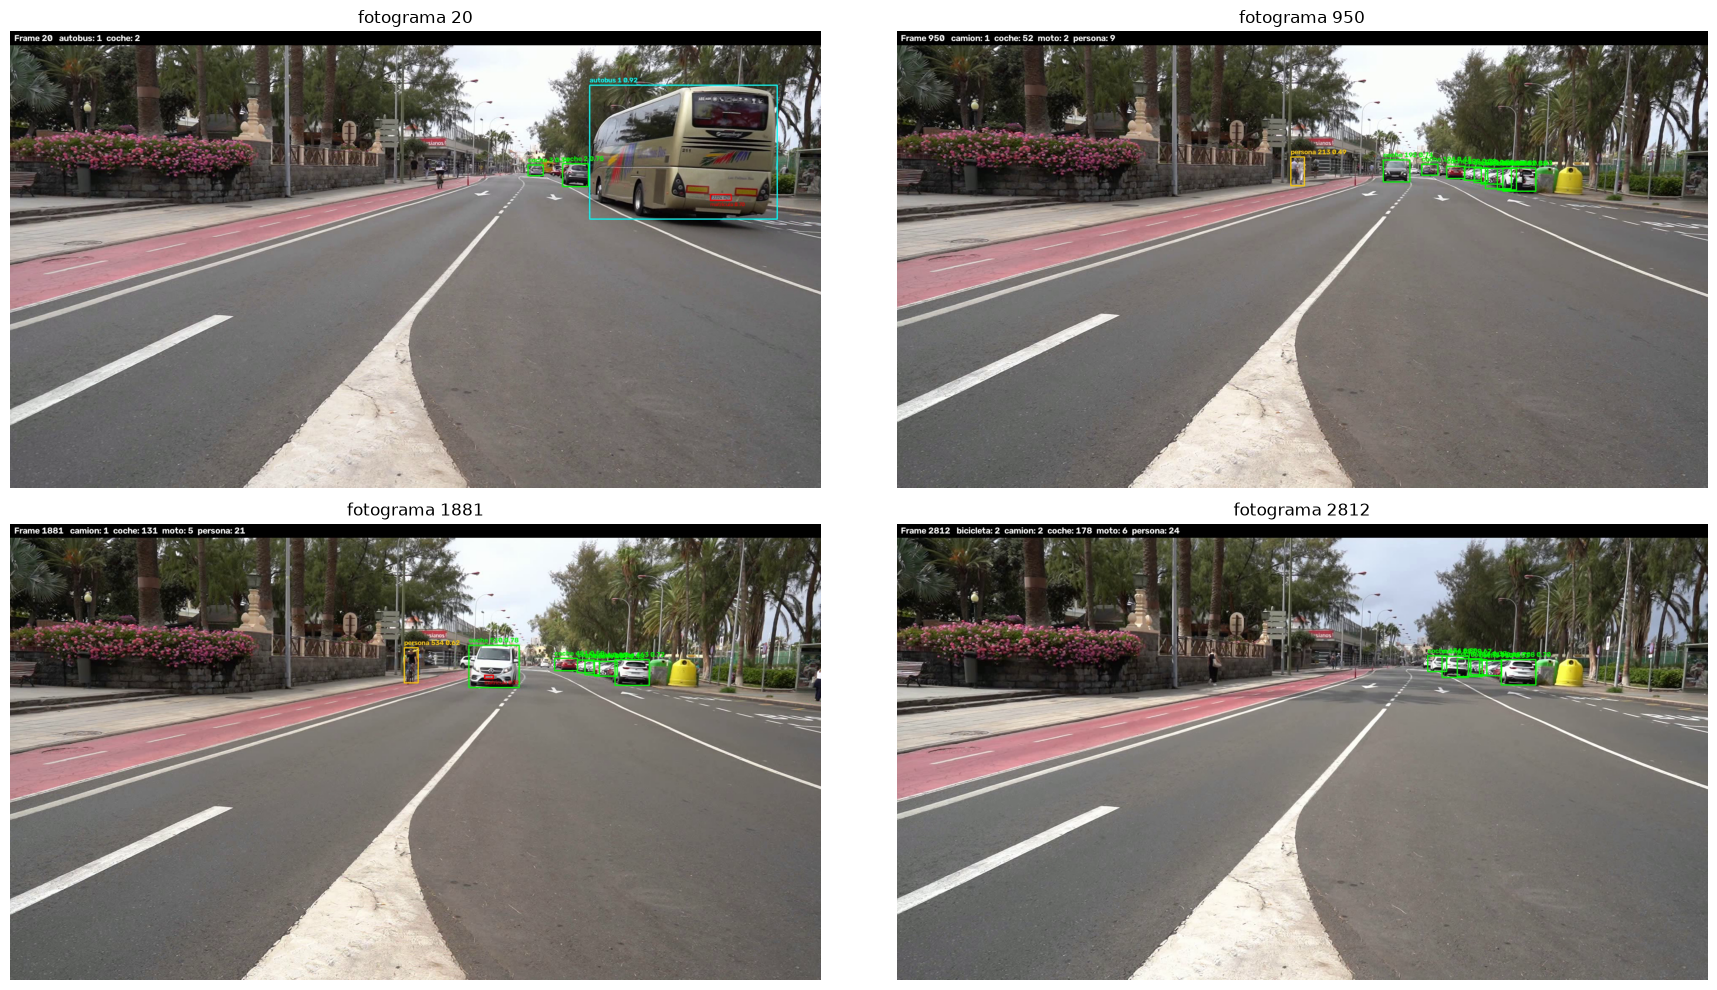

In [9]:
# Algunos fotogramas del vídeo resultado
cap = cv2.VideoCapture(os.path.join(OUT_DIR, 'resultado.mp4'))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axs = plt.subplots(2, 2, figsize=(18, 10))
for ax, f in zip(axs.ravel(), np.linspace(20, total - 20, 4).astype(int)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, img = cap.read()
    ax.imshow(img[:, :, ::-1]); ax.set_title(f'fotograma {f}'); ax.axis('off')
cap.release(); plt.tight_layout(); plt.show()

## 4. Extras

### 4.1 Flujo de personas y vehículos por dirección

Para cada track válido se compara la posición del centro al inicio y al final de su trayectoria (media de los primeros y últimos
fotogramas para suavizar). Según el desplazamiento dominante se asigna una dirección: **izquierda / derecha** (horizontal) o
**arriba / abajo** (vertical, en esta cámara equivale a alejarse / acercarse). Si el desplazamiento es menor que el 5 % del ancho
de la imagen se considera **parado**. Además se indica si el objeto **sale de la imagen** y por qué borde (su último contenedor toca el borde
y desaparece antes del final del vídeo).

In [10]:
def direccion(t, umbral=0.05 * W):
    c = np.array(t['centros'])
    k = max(1, min(5, len(c) // 3))
    dx, dy = c[-k:].mean(0) - c[:k].mean(0)
    if max(abs(dx), abs(dy)) < umbral:
        return 'parado'
    if abs(dx) >= abs(dy):
        return 'derecha' if dx > 0 else 'izquierda'
    return 'abajo' if dy > 0 else 'arriba'

ult_caja = df.sort_values('fotograma').groupby('identificador_tracking').last()
def borde_salida(tid, t, margen=10):
    if t['frames'][-1] >= nf - 2:
        return 'sigue en imagen'
    x1, y1, x2, y2 = ult_caja.loc[tid, ['x1', 'y1', 'x2', 'y2']]
    bordes = [b for b, cond in [('izquierda', x1 <= margen), ('derecha', x2 >= W - margen),
                                ('arriba', y1 <= margen), ('abajo', y2 >= H - margen)] if cond]
    return '/'.join(bordes) if bordes else 'desaparece dentro'

flujo = pd.DataFrame([{'id': tid, 'clase': CLASES[t['cls']], 'frames': len(t['frames']),
                       'direccion': direccion(t), 'salida': borde_salida(tid, t)} for tid, t in validos.items()])
display(pd.crosstab(flujo['clase'], flujo['direccion'], margins=True, margins_name='total'))
display(pd.crosstab(flujo['clase'], flujo['salida'], margins=True, margins_name='total'))
flujo.to_csv(os.path.join(OUT_DIR, 'flujo.csv'), index=False)

direccion,derecha,izquierda,parado,total
clase,,,,
bicicleta,0,2,0,2
camion,0,1,1,2
coche,4,23,153,180
moto,3,3,0,6
persona,9,3,12,24
total,16,32,166,214


salida,derecha,desaparece dentro,izquierda,izquierda/arriba,sigue en imagen,total
clase,,,,,,
bicicleta,0,1,1,0,0,2
camion,0,1,0,1,0,2
coche,3,161,11,0,5,180
moto,3,2,1,0,0,6
persona,1,20,3,0,0,24
total,7,185,16,1,5,214


### 4.2 Anonimización

Durante el mismo procesamiento se genera `resultados/anonimizado.mp4`, donde se aplica un desenfoque gaussiano al contenedor de cada
persona y a cada matrícula detectada.

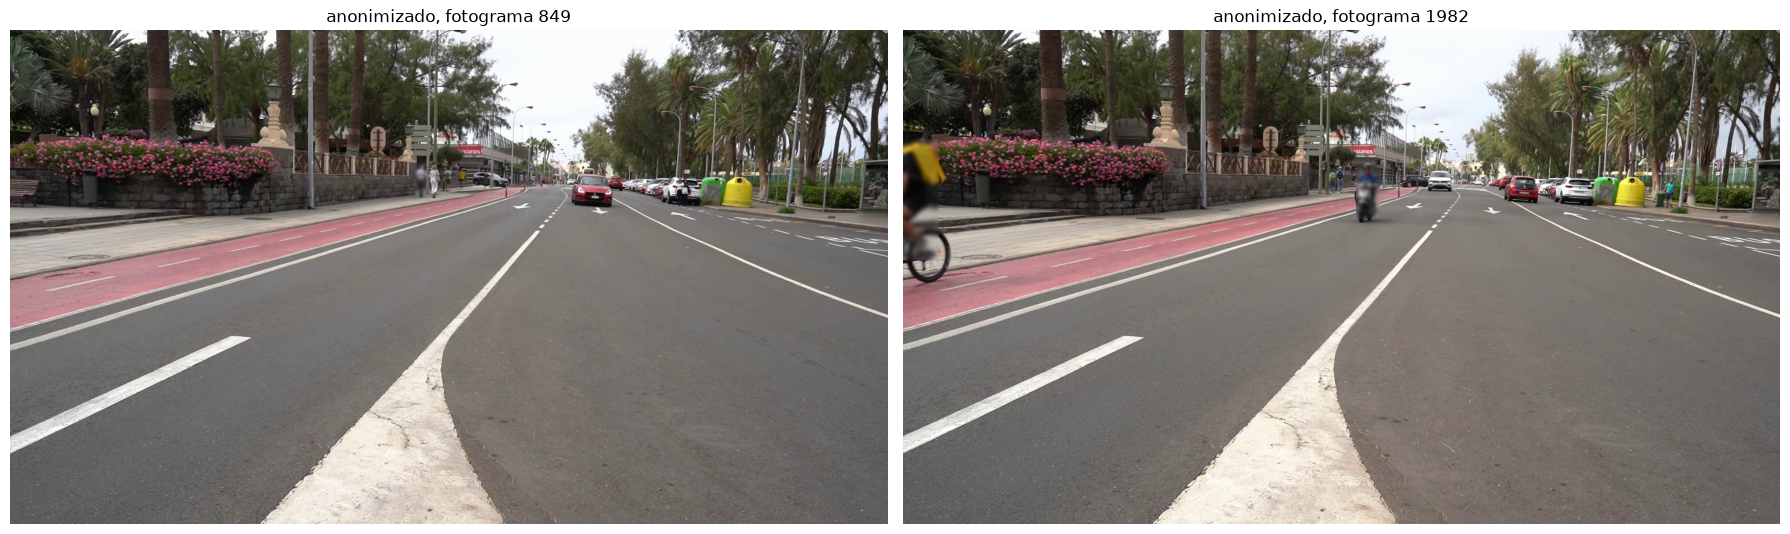

In [11]:
cap = cv2.VideoCapture(os.path.join(OUT_DIR, 'anonimizado.mp4'))
fig, axs = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, f in zip(axs, [int(total * 0.3), int(total * 0.7)]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, img = cap.read()
    ax.imshow(img[:, :, ::-1]); ax.set_title(f'anonimizado, fotograma {f}'); ax.axis('off')
cap.release(); plt.tight_layout(); plt.show()